# Controlled versus essential mutation for the TSP: analysis

This notebook rebuilds every table and figure of the study from the raw files in `data/`.
Run it from the `notebooks/` folder. Tables go to `results/` (CSV and LaTeX) and figures to `figures/`.

| Folder | Experiment | Program |
|---|---|---|
| `data/E1_benchmark` | 30 instances, 8 variants, 2000 generations | `src/em_vs_c.cpp` |
| `data/E2_trajectories` | 6 instances, checkpoints up to 2000 generations | `src/em_vs_c_diag.cpp` |
| `data/E3_long_budget` | d493 and u574, checkpoints up to 10,000 generations | `src/em_vs_c_diag.cpp` |
| `data/E4_large_population` | d493 and u574, 20,000 generations, larger population | `src/em_vs_c.cpp` |
| `data/CEM` | controlled essential mutation, 30 instances, E1 settings | `src/em_vs_c_cem.cpp` |
| `data/E5_CEM_high_rate` | controlled essential mutation, $N=200$, $p_m=0.05$ | `src/em_vs_c_cem.cpp` |

In [1]:
import os, glob, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from scipy import stats

ROOT = '..'
DATA, RES, FIG, INP = f'{ROOT}/data', f'{ROOT}/results', f'{ROOT}/figures', f'{ROOT}/inputs'
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)
pd.set_option('display.width', 200)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e5e5e5',
                     'grid.linewidth': 0.6, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
COL = {'swap': '#D55E00', 'ins': '#0072B2', '2opt': '#009E73', 'rev': '#CC79A7', 'cem': '#000000', 'em': '#7f7f7f'}
MRK = {'swap': 'o', 'ins': 's', '2opt': '^', 'rev': 'D'}
NAME = {'swap': 'Swap', 'ins': 'Insertion', '2opt': '2-opt', 'rev': 'Reversion'}
MOVES = ['swap', '2opt', 'rev', 'ins']
CTRL = [f'C_{m}' for m in MOVES]; EMV = [f'EM_{m}' for m in MOVES]
LAB = {'CEM': 'CEM', **{f'C_{m}': f'Ctrl. {NAME[m].lower()}' for m in MOVES}, **{f'EM_{m}': f'EM {NAME[m].lower()}' for m in MOVES}}
BINS = [0, 100, 200, 500, 1000, 10**9]; BLAB = ['≤100', '101–200', '201–500', '501–1000', '>1000']

def save(df, name, fmt='%.2f', index=True):
    df.to_csv(f'{RES}/{name}.csv', index=index)
    with open(f'{RES}/{name}.tex', 'w') as f:
        f.write(df.to_latex(index=index, float_format=lambda x: fmt % x, escape=True))
    return df

def one(pattern):
    f = glob.glob(pattern)
    assert len(f) == 1, pattern
    return f[0]

def runs(folder, inst, var):
    return pd.read_csv(one(f'{DATA}/{folder}/{inst}_{var}_runs_*.csv'))

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for k, i in enumerate(o):
        run = max(run, min(1, (m - k) * p[i])); adj[i] = run
    return adj

def logx(ax, ticks=(50, 100, 200, 500, 1000, 2000)):
    ax.set_xscale('log'); ax.set_xticks(ticks); ax.set_xticklabels([str(t) for t in ticks])
    ax.minorticks_off(); ax.set_xlabel('Number of cities $n$')

def plain(ax, axis='y'):
    f = mt.FuncFormatter(lambda v, _: f'{v:g}')
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(f)
    (ax.yaxis if axis == 'y' else ax.xaxis).set_minor_formatter(mt.NullFormatter())

## 1. Settings of each experiment

Attempts per generation is the expected number of mutation trials, $N\,p_m\,n$.

In [2]:
SET = pd.DataFrame([
    ['E1', '30 TSPLIB, n = 51–1432', 2000, 30, 300, 60, 0.005],
    ['E2', 'kroA100, ch150, a280, d493, u574, fl1400', 2000, 20, 200, 50, 0.005],
    ['E3', 'd493, u574', 10000, 20, 200, 50, 0.005],
    ['E4', 'd493, u574', 20000, 50, 500, 100, 0.005],
    ['CEM (in E1)', '30 TSPLIB, n = 51–1432', 2000, 30, 300, 60, 0.005],
    ['E5 (CEM)', '30 TSPLIB, n = 51–1432', 2000, 30, 200, 50, 0.05]],
    columns=['Exp.', 'Instances', 'G', 'Runs', 'N', 'E', 'p_m']).set_index('Exp.')
SET['Attempts / gen.'] = [f'{N * p:g} n' for N, p in zip(SET.N, SET.p_m)]
save(SET, 'T2_settings', '%g')

,Instances,G,Runs,N,E,p_m,Attempts / gen.
Exp.,,,,,,,
E1,"30 TSPLIB, n = 51–1432",2000,30,300,60,0.005,1.5 n
E2,"kroA100, ch150, a280, d493, u574, fl1400",2000,20,200,50,0.005,1 n
E3,"d493, u574",10000,20,200,50,0.005,1 n
E4,"d493, u574",20000,50,500,100,0.005,2.5 n
CEM (in E1),"30 TSPLIB, n = 51–1432",2000,30,300,60,0.005,1.5 n
E5 (CEM),"30 TSPLIB, n = 51–1432",2000,30,200,50,0.050,10 n


## 2. E1: EM against controlled on 30 instances

In [3]:
e1 = pd.read_csv(one(f'{DATA}/E1_benchmark/ALL_EMvsC_summary_*.csv'))
cem = pd.read_csv(one(f'{DATA}/CEM/ALL_CEM_summary_*.csv'))
df = pd.concat([e1, cem], ignore_index=True)
df['n'] = df.Instance.str.extract(r'(\d+)$')[0].astype(int)
n = df.groupby('Instance').n.first().sort_values()
P = lambda c: df.pivot(index='Instance', columns='Variant', values=c).loc[n.index]
AVG, STD, BEST, CONV, TIME = P('Avg'), P('Std'), P('Best'), P('AvgConvGen'), P('AvgTime')
PMW = e1.pivot(index='Instance', columns='Variant', values='p_vs_twin').loc[n.index]
sizebin = pd.cut(n, BINS, labels=BLAB)
print(len(n), 'instances')

30 instances


In [4]:
rows = []
for m in MOVES:
    em, c = AVG[f'EM_{m}'], AVG[f'C_{m}']
    red = 100 * (em - c) / em
    w = stats.wilcoxon(c, em)
    sig = PMW[f'C_{m}'] < 0.05
    win = int((sig & (c < em)).sum()); loss = int((sig & (c > em)).sum())
    rho = stats.spearmanr(n, red)
    rows.append([NAME[m], w.statistic, w.pvalue, f'{int((c < em).sum())}/30', f'{win} / {30 - win - loss} / {loss}',
                 red.median(), rho.correlation, rho.pvalue])
T3 = save(pd.DataFrame(rows, columns=['Move', 'W', 'p', 'Ctrl. better', 'Win/tie/loss', 'Median red. (%)', 'rho_s', 'p(rho_s)']).set_index('Move'),
          'T3_em_vs_controlled', '%.3g')
T3

,W,p,Ctrl. better,Win/tie/loss,Median red. (%),rho_s,p(rho_s)
Move,,,,,,,
Swap,9.0,6.146729e-08,28/30,25 / 5 / 0,42.416133,0.973749,1.539812e-19
2-opt,0.0,1.862645e-09,30/30,30 / 0 / 0,46.102625,0.257397,1.696953e-01
Reversion,0.0,1.862645e-09,30/30,30 / 0 / 0,46.189516,0.243604,1.945541e-01
Insertion,5.0,1.862645e-08,28/30,26 / 4 / 0,44.744256,0.614683,3.014058e-04


In [5]:
winner = AVG[CTRL].idxmin(axis=1)
red = pd.DataFrame({NAME[m]: 100 * (AVG[f'EM_{m}'] - AVG[f'C_{m}']) / AVG[f'EM_{m}'] for m in MOVES})
T4 = red.groupby(sizebin, observed=True).median()
T4.insert(0, 'Best by mean rank', AVG[CTRL].rank(axis=1).groupby(sizebin, observed=True).mean().idxmin(axis=1).str[2:])
T4.insert(0, 'Instance winners', winner.groupby(sizebin, observed=True).apply(
    lambda s: '; '.join(f'{k[2:]} x{v}' for k, v in s.value_counts().items())))
T4.insert(0, 'Inst.', sizebin.value_counts().sort_index())
save(T4, 'T4_winner_by_size', '%.1f')

,Inst.,Instance winners,Best by mean rank,Swap,2-opt,Reversion,Insertion
n,,,,,,,
≤100,4,rev x2; 2opt x2,2opt,0.459453,9.313600,10.678523,0.037109
101–200,5,rev x3; ins x2,rev,6.223752,49.563371,50.996509,25.119292
201–500,6,ins x4; rev x1; swap x1,ins,36.296290,47.327360,47.481409,45.412572
501–1000,5,swap x4; rev x1,swap,49.016331,44.317891,44.778764,50.031868
>1000,10,swap x9; 2opt x1,swap,61.983839,46.761653,46.624820,44.897897


In [6]:
def rank_table(cols):
    A = AVG[cols]; rk = A.rank(axis=1); gap = 100 * A.sub(A.min(axis=1), axis=0).div(A.min(axis=1), axis=0)
    return pd.DataFrame({'Mean rank': rk.mean(), 'Mean gap (%)': gap.mean(), 'Median gap (%)': gap.median(),
                         'Wins': A.idxmin(axis=1).value_counts().reindex(cols).fillna(0).astype(int)}).sort_values('Mean rank')

def pair_tests(cols):
    out = [[a, b, int((AVG[a] < AVG[b]).sum()), stats.wilcoxon(AVG[a], AVG[b]).pvalue] for a, b in itertools.combinations(cols, 2)]
    out = pd.DataFrame(out, columns=['A', 'B', 'A better', 'p']); out['p_Holm'] = holm(out.p)
    return out

S1 = save(rank_table(CTRL + EMV), 'TS1_ranks_8', '%.2f')
H8 = pair_tests(CTRL + EMV)
same = H8.A.str[:2] == H8.B.str[:2]
print('smallest p_Holm inside a family:', round(H8[same].p_Holm.min(), 3))
S1

smallest p_Holm inside a family: 0.372


,Mean rank,Mean gap (%),Median gap (%),Wins
C_rev,2.300000,20.879037,25.917177,7
C_2opt,2.500000,21.057210,26.182611,3
C_ins,2.966667,24.279056,22.326637,6
C_swap,3.000000,24.670277,9.134924,14
EM_ins,6.066667,110.160655,113.507331,0
EM_swap,6.166667,114.595891,106.665132,0
EM_2opt,6.233333,128.827499,143.962227,0
EM_rev,6.766667,129.901387,145.858946,0


In [7]:
S2 = pd.DataFrame({
    'EM time (s)': TIME[EMV].mean(axis=1).groupby(sizebin, observed=True).mean(),
    'Ctrl. time (s)': TIME[CTRL].mean(axis=1).groupby(sizebin, observed=True).mean(),
    'Ratio': pd.concat([TIME[f'EM_{m}'] / TIME[f'C_{m}'] for m in MOVES], axis=1).mean(axis=1).groupby(sizebin, observed=True).mean(),
    'EM conv.': CONV[EMV].mean(axis=1).groupby(sizebin, observed=True).mean(),
    'Ctrl. conv.': CONV[CTRL].mean(axis=1).groupby(sizebin, observed=True).mean()})
save(S2, 'TS2_time_conv', '%.2f')

,EM time (s),Ctrl. time (s),Ratio,EM conv.,Ctrl. conv.
n,,,,,
≤100,0.681799,0.338776,1.990392,1487.512500,759.950000
101–200,1.522351,0.718851,2.136858,1971.021667,1826.635000
201–500,3.380388,1.491931,2.306833,1967.820833,1990.713889
501–1000,7.021414,2.826625,2.586850,1948.758333,1998.301667
>1000,15.341541,5.062433,3.101297,1917.405833,1999.007500


In [8]:
BKS = dict(eil51=426, berlin52=7542, st70=675, kroA100=21282, bier127=118282, ch150=6528, pr152=73682, rat195=2323,
           kroA200=29368, pr226=80369, a280=2579, pr299=48191, lin318=42029, pr439=107217, d493=35002, u574=36905,
           rat575=6773, p654=34643, u724=41910, rat783=8806, pr1002=259045, u1060=224094, vm1084=239297,
           pcb1173=56892, d1291=50801, rl1304=252948, rl1323=270199, nrw1379=56638, fl1400=20127, u1432=152970)
gap = lambda L, i: 100 * (L - BKS[i]) / BKS[i]
T5 = pd.DataFrame([[n[i], BKS[i], gap(BEST.loc[i, CTRL].min(), i), gap(BEST.loc[i, 'CEM'], i), gap(BEST.loc[i, EMV].min(), i)]
                   for i in n.index], index=n.index, columns=['n', 'BKS', 'Best ctrl. (%)', 'CEM (%)', 'Best EM (%)'])
save(T5, 'T5_gap_bks', '%.1f')

,n,BKS,Best ctrl. (%),CEM (%),Best EM (%)
Instance,,,,,
eil51,51,426,2.065728,15.375587,4.178404
berlin52,52,7542,0.031822,22.235481,1.852294
st70,70,675,1.511111,44.948148,7.733333
kroA100,100,21282,3.217273,70.248567,27.652476
bier127,127,118282,4.442519,41.430987,28.841497
ch150,150,6528,19.842218,59.713542,51.948529
pr152,152,73682,9.525121,178.796857,108.725062
rat195,195,2323,35.858803,68.919501,90.602669
kroA200,200,29368,45.468878,113.398597,120.817557


### Figures 2 and 3

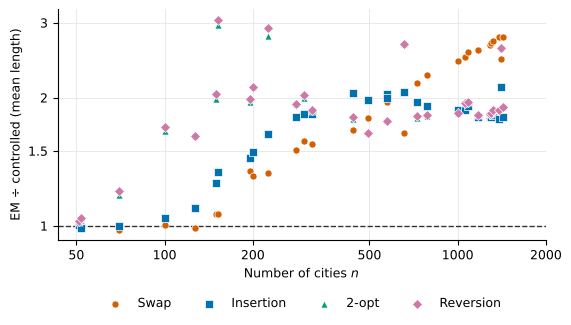

In [9]:
fig, ax = plt.subplots(figsize=(6.3, 3.0))
for m in ['swap', 'ins', '2opt', 'rev']:
    ax.scatter(n, AVG[f'EM_{m}'] / AVG[f'C_{m}'], s=26, marker=MRK[m], c=COL[m], label=NAME[m], edgecolor='white', lw=0.5, zorder=3)
ax.axhline(1, ls='--', c='#333', lw=1); logx(ax)
ax.set_yscale('log'); ax.set_yticks([1, 1.5, 2, 3]); ax.set_yticklabels(['1', '1.5', '2', '3']); ax.minorticks_off()
ax.set_ylabel('EM ÷ controlled (mean length)')
ax.legend(ncol=4, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.2))
fig.savefig(f'{FIG}/fig3_ratio_vs_n.png'); plt.show()

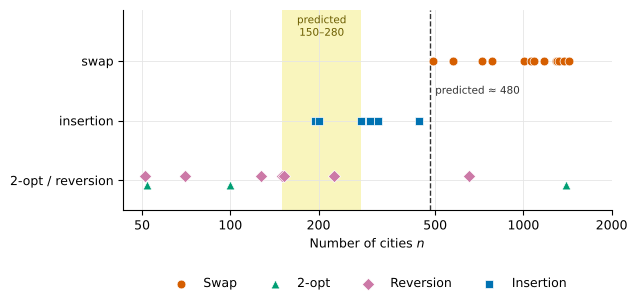

In [10]:
lev = {'C_swap': 2, 'C_ins': 1, 'C_2opt': 0, 'C_rev': 0}
fig, ax = plt.subplots(figsize=(6.3, 2.6))
ax.axvspan(150, 280, color='#f0e442', alpha=0.35, lw=0)
ax.axvline(480, ls='--', c='#333', lw=1)
for v in CTRL:
    m = v[2:]; k = winner[winner == v].index
    ax.scatter(n[k], np.full(len(k), lev[v] + {'2opt': -0.08, 'rev': 0.08}.get(m, 0)), marker=MRK[m], c=COL[m], s=40,
               label=NAME[m], edgecolor='white', lw=0.5, zorder=3)
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(['2-opt / reversion', 'insertion', 'swap']); ax.set_ylim(-0.5, 2.85)
ax.text(205, 2.42, 'predicted\n150–280', ha='center', fontsize=7.5, color='#6b5d00')
ax.text(500, 1.45, 'predicted ≈ 480', fontsize=7.5, color='#333')
logx(ax); ax.legend(ncol=4, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.28))
fig.savefig(f'{FIG}/fig4_winners_vs_n.png'); plt.show()

## 3. A closer look at a280 (Table S3, Figure 4, Figure S1)

In [11]:
def read_tsp(path):
    xy, on = [], False
    for line in open(path):
        t = line.split()
        if not t: continue
        if t[0].upper().startswith('NODE_COORD_SECTION'): on = True; continue
        if t[0].upper() == 'EOF': break
        if on and len(t) >= 3: xy.append((float(t[1]), float(t[2])))
    return np.array(xy)

XY = read_tsp(f'{INP}/a280.tsp')
S3 = df[df.Instance == 'a280'].set_index('Variant')[['Best', 'Avg', 'Std', 'AvgConvGen', 'AvgTime']]
S3 = S3.loc[['EM_swap', 'C_swap', 'EM_2opt', 'C_2opt', 'EM_rev', 'C_rev', 'EM_ins', 'C_ins', 'CEM']]
save(S3, 'TS3_a280', '%.1f')

,Best,Avg,Std,AvgConvGen,AvgTime
Variant,,,,,
EM_swap,9614.4,10239.373333,360.384837,1944.466667,3.323580
C_swap,6070.6,6806.133333,418.942552,1988.300000,1.276349
EM_2opt,11983.3,12694.560000,387.145275,1980.133333,3.084479
C_2opt,6007.7,6565.363333,229.075630,1995.000000,1.793668
EM_rev,11849.6,12760.213333,448.248945,1977.500000,4.840222
C_rev,5957.5,6602.080000,243.439192,1995.900000,1.262201
EM_ins,8615.2,9661.876667,490.632452,1994.100000,2.337077
C_ins,4858.0,5357.883333,235.792141,1997.600000,1.272657
CEM,6203.2,7128.616667,384.432917,1991.433333,1.559335


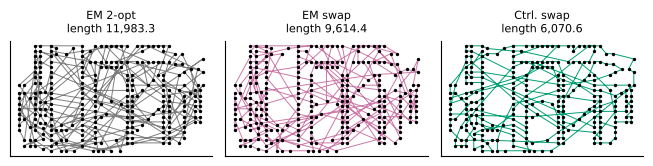

In [12]:
def tour_of(r):
    return np.array([int(c) for c in r.strip('[]').split(';')]) - 1

def tour_len(t):
    p = XY[np.r_[t, t[0]]]
    return np.sqrt(((p[1:] - p[:-1]) ** 2).sum(axis=1)).sum()

fig, axs = plt.subplots(1, 3, figsize=(6.6, 2.6))
for ax, v, c in zip(axs, ['EM_2opt', 'EM_swap', 'C_swap'], [COL['em'], COL['rev'], COL['2opt']]):
    r = runs('E1_benchmark', 'a280', v); b = r.loc[r.Best.idxmin()]
    t = tour_of(b.Plot); p = XY[np.r_[t, t[0]]]
    ax.plot(p[:, 0], p[:, 1], c=c, lw=0.7); ax.scatter(XY[:, 0], XY[:, 1], s=2, c='k', zorder=3)
    ax.set_title(f'{LAB[v]}\nlength {tour_len(t):,.1f}', fontsize=8); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_aspect('equal')
fig.tight_layout(); fig.savefig(f'{FIG}/fig5_a280_tours.png'); plt.show()

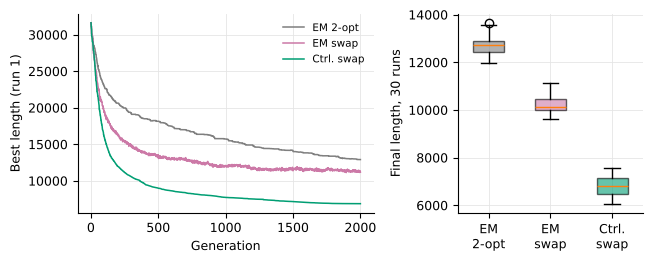

worst ctrl. swap run 7583.5 | best EM swap run 9614.4


In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.6, 2.7), gridspec_kw={'width_ratios': [1.6, 1]})
box = []
for v, c in [('EM_2opt', COL['em']), ('EM_swap', COL['rev']), ('C_swap', COL['2opt'])]:
    fr = pd.read_csv(one(f'{DATA}/E1_benchmark/a280_{v}_FR_*.csv')).Best
    a1.plot(np.arange(1, len(fr) + 1), fr, c=c, lw=1.1, label=LAB[v])
    box.append(runs('E1_benchmark', 'a280', v).Best)
a1.set_xlabel('Generation'); a1.set_ylabel('Best length (run 1)'); a1.legend(frameon=False, fontsize=7.5)
bp = a2.boxplot(box, patch_artist=True, widths=0.5)
for patch, c in zip(bp['boxes'], [COL['em'], COL['rev'], COL['2opt']]): patch.set_facecolor(c); patch.set_alpha(0.6)
a2.set_xticks([1, 2, 3]); a2.set_xticklabels(['EM\n2-opt', 'EM\nswap', 'Ctrl.\nswap']); a2.set_ylabel('Final length, 30 runs')
fig.tight_layout(); fig.savefig(f'{FIG}/figS1_a280_convergence.png'); plt.show()
print('worst ctrl. swap run', box[2].max(), '| best EM swap run', box[1].min())

## 4. Checkpoint runs (E2 and E3)

In [14]:
E2 = pd.read_csv(one(f'{DATA}/E2_trajectories/DIAG_*.csv'))
E3 = pd.read_csv(one(f'{DATA}/E3_long_budget/DIAG_*.csv'))
NN = {'kroA100': 100, 'ch150': 150, 'a280': 280, 'd493': 493, 'u574': 574, 'fl1400': 1400}

def mean_bsf(D):
    return D[D.Variant.isin(CTRL)].groupby(['Instance', 'Gen', 'Variant']).BestSoFar.mean().unstack()[CTRL]

M2, M3 = mean_bsf(E2), mean_bsf(E3)

def leader(row):
    v = {'swap': row.C_swap, 'insertion': row.C_ins, '2-opt/rev.': (row.C_2opt + row.C_rev) / 2}
    return min(v, key=v.get)

S4 = M2[M2.index.get_level_values('Gen') > 1].apply(leader, axis=1).unstack(0)[list(NN)]
save(S4, 'TS4_leader_E2')

Instance,kroA100,ch150,a280,d493,u574,fl1400
Gen,,,,,,
10,swap,insertion,insertion,swap,insertion,swap
25,insertion,swap,swap,swap,swap,swap
50,swap,swap,swap,swap,swap,swap
100,swap,swap,swap,swap,swap,swap
200,swap,swap,swap,swap,swap,swap
300,insertion,swap,swap,swap,swap,swap
500,insertion,swap,swap,swap,swap,swap
750,insertion,insertion,swap,swap,swap,swap
1000,2-opt/rev.,insertion,swap,swap,swap,swap


In [15]:
S5 = M3[M3.index.get_level_values('Gen') >= 100].round(0)
save(S5, 'TS5_bestsofar_E3', '%.0f')

Variant           C_swap    C_2opt     C_rev     C_ins
Instance Gen                                          
d493     100    254646.0  337049.0  337912.0  318341.0
         500    138249.0  227898.0  228472.0  202920.0
         1000   113856.0  175118.0  175071.0  145566.0
         2000    98374.0  127262.0  126826.0   99298.0
         3000    92143.0  101737.0  101207.0   80441.0
         4000    88916.0   83407.0   83212.0   69488.0
         5000    86877.0   69674.0   70288.0   62815.0
         6000    85595.0   60731.0   60820.0   58752.0
         8000    84373.0   48695.0   48465.0   54195.0
         10000   83897.0   42500.0   42450.0   52141.0
u574     100    389413.0  514349.0  514395.0  488504.0
         500    205931.0  342903.0  341703.0  317331.0
         1000   167291.0  259321.0  258290.0  229160.0
         2000   141363.0  184806.0  184040.0  154142.0
         3000   130510.0  147121.0  146444.0  120794.0
         4000   123645.0  120489.0  120632.0  101911.0
         5000   119049.0   99563.0  100401.0   90043.0
         6000   116220.0   84419.0   85149.0   81434.0
         8000   113011.0   65095.0   65517.0   71407.0
         10000  111876.0   53504.0   53666.0   65936.0

In [16]:
rows = []
for inst in ['d493', 'u574']:
    d = E3[E3.Instance == inst]
    W = d.pivot_table(index='Run', columns=['Gen', 'Variant'], values='BestSoFar')
    sub = []
    for g in [2000, 3000, 6000, 8000, 10000]:
        for a, b in [('C_swap', 'C_ins'), ('C_ins', 'C_2opt')]:
            x, y = W[(g, a)], W[(g, b)]
            sub.append([inst, g, f'{a} < {b}', int((x < y).sum()), stats.wilcoxon(x, y).pvalue])
    s = pd.DataFrame(sub, columns=['Instance', 'Gen', 'Pair', 'Runs A better', 'p'])
    allp = []
    for g in sorted(d.Gen.unique()):
        if g == 1: continue
        for a, b in [('C_swap', 'C_ins'), ('C_ins', 'C_2opt'), ('C_swap', 'C_2opt'), ('C_2opt', 'C_rev')]:
            allp.append(((g, a, b), stats.wilcoxon(W[(g, a)], W[(g, b)]).pvalue))
    adj = dict(zip([k for k, _ in allp], holm([p for _, p in allp])))
    s['p_Holm'] = [adj[(g, *pr.split(' < '))] for g, pr in zip(s.Gen, s.Pair)]
    rows.append(s)
S6 = save(pd.concat(rows).set_index(['Instance', 'Gen', 'Pair']), 'TS6_paired_E3', '%.3g')
S6

Runs A better         p    p_Holm
Instance Gen   Pair                                             
d493     2000  C_swap < C_ins             12  0.570597  1.000000
               C_ins < C_2opt             20  0.000002  0.000076
         3000  C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt             20  0.000002  0.000076
         6000  C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt             14  0.003654  0.043854
         8000  C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt              0  0.000002  0.000076
         10000 C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt              0  0.000002  0.000076
u574     2000  C_swap < C_ins             19  0.000004  0.000076
               C_ins < C_2opt             20  0.000002  0.000076
         3000  C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt             20  0.000002  0.000076
         6000  C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt             13  0.009436  0.113228
         8000  C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt              0  0.000002  0.000076
         10000 C_swap < C_ins              0  0.000002  0.000076
               C_ins < C_2opt              0  0.000002  0.000076

In [17]:
grid = sorted(E3.Gen.unique()); prev = {g: grid[i - 1] for i, g in enumerate(grid) if i}
A = E3[(E3.Gen > 1) & E3.Variant.isin(CTRL)].groupby(['Instance', 'Gen', 'Variant'])[['Attempts', 'Accepted', 'GainSum']].sum()
A['acc_pct'] = 100 * A.Accepted / A.Attempts
A['gain_per_acc'] = A.GainSum / A.Accepted.replace(0, np.nan)
A = A.reset_index(); A['window'] = [f'{prev[g] + 1}–{g}' for g in A.Gen]
S7 = A.pivot_table(index=['Instance', 'Gen', 'window'], columns='Variant', values=['acc_pct', 'gain_per_acc'])
save(S7, 'TS7_move_stats_E3', '%.3g')
print('attempts per generation, d493 C_swap:', round(A[(A.Instance == 'd493') & (A.Variant == 'C_swap')].Attempts.sum() / 20 / (grid[-1] - 1), 1))

attempts per generation, d493 C_swap: 492.0


### Crossover generations

The crossover is the last change from "A shorter" to "B shorter" of the mean best-so-far,
interpolated linearly inside its bracket: $g^* = g_k + (g_{k+1}-g_k)\,\frac{-D_k}{D_{k+1}-D_k}$.
The interval comes from 1000 paired bootstrap resamples of runs.

In [18]:
def crossover(W, A, B, idx=None):
    m = (W if idx is None else W.loc[idx]).mean()
    g = sorted(set(m.index.get_level_values(0)))
    D = np.array([m[(x, A)] - m[(x, B)] for x in g])
    k = [i for i in range(len(g) - 1) if D[i] < 0 and D[i + 1] > 0]
    if not k: return np.nan, np.nan, np.nan
    i = k[-1]
    return g[i] + (g[i + 1] - g[i]) * (-D[i]) / (D[i + 1] - D[i]), g[i], g[i + 1]

rng = np.random.default_rng(1)
rows = []
for src, D in [('E2', E2), ('E3', E3)]:
    for inst in D.Instance.unique():
        d = D[D.Instance == inst].copy()
        W = d.pivot_table(index='Run', columns=['Gen', 'Variant'], values='BestSoFar')
        for A_, B_ in [('C_swap', 'C_ins'), ('C_ins', 'C_2opt')]:
            est, lo, hi = crossover(W, A_, B_)
            bs = [crossover(W, A_, B_, rng.choice(W.index, len(W.index)))[0] for _ in range(1000)] if not np.isnan(est) else [np.nan]
            ci = np.nanpercentile(bs, [2.5, 97.5]) if not np.all(np.isnan(bs)) else [np.nan, np.nan]
            rows.append([src, inst, NN[inst], f'{B_} > {A_}', lo, hi, est, *ci])
T7 = pd.DataFrame(rows, columns=['Run set', 'Instance', 'n', 'Change', 'From', 'To', 'Estimate', 'CI low', 'CI high'])
T7 = T7.sort_values(['Change', 'n', 'Run set'])
save(T7.set_index(['Change', 'Instance', 'Run set']), 'T7_crossovers', '%.0f')

n    From      To     Estimate       CI low      CI high
Change         Instance Run set                                                             
C_2opt > C_ins kroA100  E2        100   750.0  1000.0   875.414966   799.423660   939.921268
               ch150    E2        150  1500.0  2000.0  1869.670695  1766.216873  1966.269681
               a280     E2        280     NaN     NaN          NaN          NaN          NaN
               d493     E2        493     NaN     NaN          NaN          NaN          NaN
                        E3        493  6000.0  8000.0  6529.239183  6277.263510  6788.222736
               u574     E2        574     NaN     NaN          NaN          NaN          NaN
                        E3        574  6000.0  8000.0  6642.131701  6306.396606  6934.902663
               fl1400   E2       1400   500.0   750.0   536.039698   482.700145   586.356399
C_ins > C_swap kroA100  E2        100   200.0   300.0   285.826449   206.677410   373.717398
               ch150    E2        150   500.0   750.0   518.867863   431.502096   627.613098
               a280     E2        280  1000.0  1500.0  1072.024743   974.165436  1186.565136
               d493     E2        493     NaN     NaN          NaN          NaN          NaN
                        E3        493  2000.0  3000.0  2073.137958  1958.025918  2231.872466
               u574     E2        574     NaN     NaN          NaN          NaN          NaN
                        E3        574  2000.0  3000.0  2568.075217  2451.719650  2669.899337
               fl1400   E2       1400     NaN     NaN          NaN          NaN          NaN

In [19]:
best = (T7.dropna(subset=['Estimate']).sort_values('Run set', ascending=False)
          .drop_duplicates(['Change', 'Instance']).query("Instance != 'fl1400'"))
for ch, g in best.groupby('Change'):
    fit = stats.linregress(np.log(g.n), np.log(g.Estimate))
    print(f'{ch}: slope b = {fit.slope:.2f} on {len(g)} instances; g*/n =', (g.Estimate / g.n).round(1).tolist())

C_2opt > C_ins: slope b = 1.14 on 4 instances; g*/n = [13.2, 11.6, 8.8, 12.5]
C_ins > C_swap: slope b = 1.23 on 5 instances; g*/n = [4.2, 4.5, 2.9, 3.5, 3.8]


### Figures 5 to 9

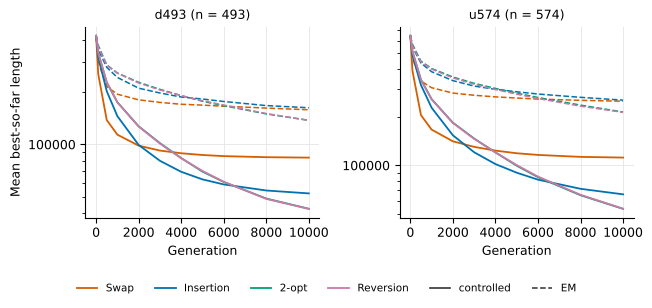

In [20]:
D3 = E3.groupby(['Instance', 'Gen', 'Variant']).BestSoFar.mean().unstack()
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.9))
for ax, inst in zip(axs, ['d493', 'u574']):
    t = D3.loc[inst]
    for m in ['swap', 'ins', '2opt', 'rev']:
        ax.plot(t.index, t[f'C_{m}'], c=COL[m], lw=1.3, label=NAME[m])
        ax.plot(t.index, t[f'EM_{m}'], c=COL[m], lw=1.1, ls='--')
    ax.set_yscale('log'); plain(ax); ax.set_title(f'{inst} (n = {NN[inst]})', fontsize=9); ax.set_xlabel('Generation')
axs[0].set_ylabel('Mean best-so-far length')
h = [plt.Line2D([], [], c=COL[m], lw=1.3) for m in ['swap', 'ins', '2opt', 'rev']] + \
    [plt.Line2D([], [], c='#333', lw=1.2), plt.Line2D([], [], c='#333', lw=1.1, ls='--')]
fig.legend(h, [NAME[m] for m in ['swap', 'ins', '2opt', 'rev']] + ['controlled', 'EM'], ncol=6, frameon=False,
           loc='lower center', bbox_to_anchor=(0.5, -0.06), fontsize=7.5)
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig(f'{FIG}/fig6_em_vs_con_long.png'); plt.show()

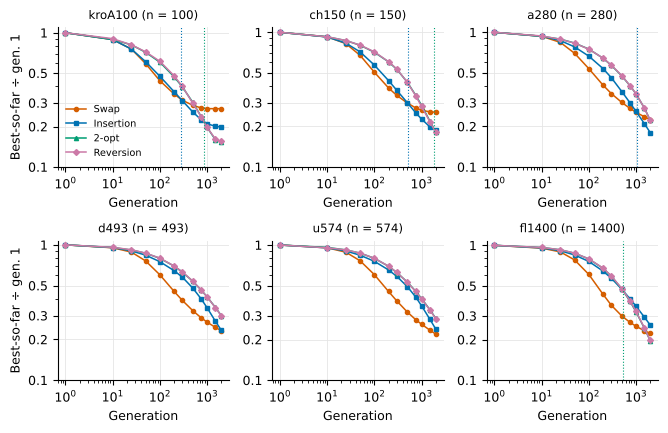

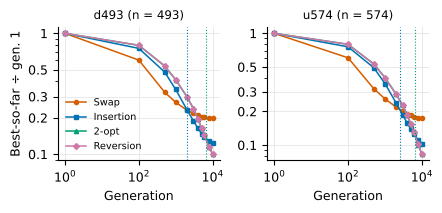

In [21]:
def traj(M, insts, name, ncol, rs):
    rows_ = int(np.ceil(len(insts) / ncol))
    fig, axs = plt.subplots(rows_, ncol, figsize=(2.25 * ncol, 2.2 * rows_), squeeze=False)
    for ax, inst in zip(axs.flat, insts):
        t = M.loc[inst]; base = t.loc[1]
        for m in ['swap', 'ins', '2opt', 'rev']:
            ax.plot(t.index, t[f'C_{m}'] / base[f'C_{m}'], c=COL[m], marker=MRK[m], ms=3, lw=1.1, label=NAME[m])
        for _, r in T7[(T7.Instance == inst) & (T7['Run set'] == rs)].dropna(subset=['Estimate']).iterrows():
            ax.axvline(r.Estimate, c=COL['ins'] if r.Change.startswith('C_ins >') else COL['2opt'], lw=0.8, ls=':')
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_yticks([0.1, 0.2, 0.3, 0.5, 1]); plain(ax); ax.set_title(f'{inst} (n = {NN[inst]})', fontsize=8.5)
        ax.set_xlabel('Generation')
    for ax in axs[:, 0]: ax.set_ylabel('Best-so-far ÷ gen. 1')
    axs.flat[0].legend(frameon=False, fontsize=7)
    fig.tight_layout(); fig.savefig(f'{FIG}/{name}.png'); plt.show()

traj(M2, list(NN), 'fig7_e2_trajectories', 3, 'E2')
traj(M3, ['d493', 'u574'], 'fig8_e3_trajectories', 2, 'E3')

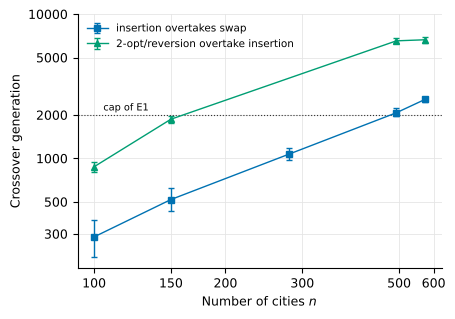

In [22]:
fig, ax = plt.subplots(figsize=(4.7, 3.3))
for ch, mk, c, lab in [('C_ins > C_swap', 's', COL['ins'], 'insertion overtakes swap'),
                       ('C_2opt > C_ins', '^', COL['2opt'], '2-opt/reversion overtake insertion')]:
    g = best[best.Change == ch].sort_values('n')
    ax.errorbar(g.n, g.Estimate, yerr=[g.Estimate - g['CI low'], g['CI high'] - g.Estimate], fmt=mk + '-', c=c, ms=5, capsize=2, lw=1, label=lab)
ax.axhline(2000, ls=':', c='#333', lw=0.8); ax.text(105, 2150, 'cap of E1', fontsize=7)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xticks([100, 150, 200, 300, 500, 600]); ax.set_xticklabels(['100', '150', '200', '300', '500', '600'])
ax.set_yticks([300, 500, 1000, 2000, 5000, 10000]); plain(ax)
ax.minorticks_off(); ax.set_xlabel('Number of cities $n$'); ax.set_ylabel('Crossover generation'); ax.legend(frameon=False, fontsize=7.5)
fig.savefig(f'{FIG}/fig9_crossover_vs_n.png'); plt.show()

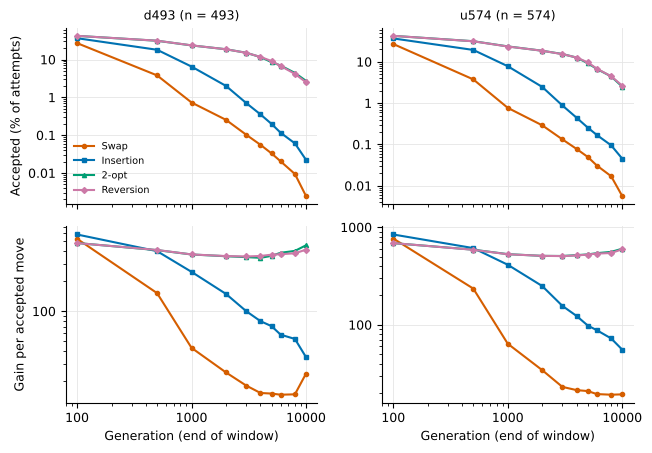

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(6.6, 4.6), sharex=True)
for j, inst in enumerate(['d493', 'u574']):
    for m in ['swap', 'ins', '2opt', 'rev']:
        s = A[(A.Instance == inst) & (A.Variant == f'C_{m}')]
        axs[0, j].plot(s.Gen, s.acc_pct.where(s.acc_pct > 0), c=COL[m], marker=MRK[m], ms=3, label=NAME[m])
        axs[1, j].plot(s.Gen, s.gain_per_acc, c=COL[m], marker=MRK[m], ms=3)
    axs[0, j].set_title(f'{inst} (n = {NN[inst]})', fontsize=9)
    for i in range(2): axs[i, j].set_xscale('log'); axs[i, j].set_yscale('log'); plain(axs[i, j]); plain(axs[i, j], 'x')
    axs[1, j].set_xlabel('Generation (end of window)')
axs[0, 0].set_ylabel('Accepted (% of attempts)'); axs[1, 0].set_ylabel('Gain per accepted move'); axs[0, 0].legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/fig10_move_stats.png'); plt.show()

## 5. Long budgets: E3 at 10,000 generations and E4 at 20,000 generations

In [24]:
def em_vs_c_final(D, label):
    fin = D[D.Gen == D.Gen.max()]
    out = []
    for inst in ['d493', 'u574']:
        for m in MOVES:
            e = fin[(fin.Instance == inst) & (fin.Variant == f'EM_{m}')].BestSoFar
            c = fin[(fin.Instance == inst) & (fin.Variant == f'C_{m}')].BestSoFar
            out.append([inst, NAME[m], e.mean(), c.mean(), e.mean() / c.mean(), stats.mannwhitneyu(e, c, alternative='two-sided').pvalue])
    return pd.DataFrame(out, columns=['Instance', 'Move', 'EM mean', 'Ctrl. mean', 'EM / ctrl.', 'p']).set_index(['Instance', 'Move'])

e3s = pd.read_csv(one(f'{DATA}/E3_long_budget/ALL_EMvsC_summary_*.csv')).set_index(['Instance', 'Variant'])
T6 = em_vs_c_final(E3, 'E3')
T6['Ctrl. conv. gen.'] = [e3s.loc[(i, f"C_{dict(zip(NAME.values(), NAME.keys()))[m]}"), 'AvgConvGen'] for i, m in T6.index]
save(T6, 'T6_E3_10000', '%.3g')

EM mean  Ctrl. mean  EM / ctrl.             p  Ctrl. conv. gen.
Instance Move                                                                         
d493     Swap       158487.690   83897.475    1.889064  6.795615e-08           8919.60
         2-opt      137742.815   42499.985    3.241009  6.795615e-08           9981.20
         Reversion  137589.155   42450.180    3.241191  6.795615e-08           9986.50
         Insertion  162788.870   52140.590    3.122114  6.795615e-08           9987.45
u574     Swap       251663.780  111876.175    2.249485  6.795615e-08           9640.60
         2-opt      215437.200   53503.795    4.026578  6.795615e-08           9989.60
         Reversion  214245.430   53666.040    3.992197  6.795615e-08           9993.10
         Insertion  255476.495   65935.975    3.874615  6.795615e-08           9990.70

In [25]:
e4 = pd.read_csv(one(f'{DATA}/E4_large_population/ALL_EMvsC_summary_*.csv')).set_index(['Instance', 'Variant'])
rows = []
for inst in ['d493', 'u574']:
    for m in MOVES:
        a, b = e4.loc[(inst, f'EM_{m}')], e4.loc[(inst, f'C_{m}')]
        rows.append([inst, NAME[m], a.Avg, b.Avg, a.Avg / b.Avg, b.p_vs_twin, b.AvgConvGen])
T6b = save(pd.DataFrame(rows, columns=['Instance', 'Move', 'EM mean', 'Ctrl. mean', 'EM / ctrl.', 'p', 'Ctrl. conv. gen.'])
           .set_index(['Instance', 'Move']), 'T6b_E4_20000', '%.4g')
T6b

EM mean  Ctrl. mean  EM / ctrl.             p  Ctrl. conv. gen.
Instance Move                                                                         
d493     Swap       125799.540   84196.090    1.494126  7.064480e-18           5713.08
         2-opt       91546.644   38630.976    2.369773  7.066070e-18          14014.64
         Reversion   92608.754   38480.952    2.406613  7.066070e-18          14262.92
         Insertion  251472.078   51040.786    4.926885  7.066070e-18          10250.92
u574     Swap       188497.344  110949.768    1.698943  7.066070e-18           6934.68
         2-opt      136424.300   41379.744    3.296886  7.066070e-18          16701.96
         Reversion  136535.070   41401.760    3.297808  7.066070e-18          16781.04
         Insertion  387031.294   60212.720    6.427733  7.066070e-18          13475.60

## 6. Controlled essential mutation (CEM)

CEM in `data/CEM` uses exactly the E1 settings and seeds, so it differs from controlled swap only in the essential-edge test.
Per-instance tests are two-sided Mann–Whitney tests on the 30 final tour lengths.

In [26]:
def cem_vs(b):
    redv = 100 * (AVG[b] - AVG['CEM']) / AVG[b]
    p = pd.Series({i: stats.mannwhitneyu(runs('CEM', i, 'CEM').Best, runs('E1_benchmark', i, b).Best, alternative='two-sided').pvalue
                   for i in n.index})
    w = stats.wilcoxon(AVG['CEM'], AVG[b]); rho = stats.spearmanr(n, redv)
    win = int(((p < 0.05) & (AVG['CEM'] < AVG[b])).sum()); loss = int(((p < 0.05) & (AVG['CEM'] > AVG[b])).sum())
    return redv, p, dict(better=int((AVG['CEM'] < AVG[b]).sum()), median_red=redv.median(), W=w.statistic, p=w.pvalue,
                         win=win, tie=30 - win - loss, loss=loss, rho=rho.correlation, p_rho=rho.pvalue)

red_em, p_em, s_em = cem_vs('EM_swap')
red_cs, p_cs, s_cs = cem_vs('C_swap')
T9a = save(pd.DataFrame([s_em, s_cs], index=['CEM vs EM swap', 'CEM vs ctrl. swap']), 'T9a_cem_tests', '%.3g')
T9a

,better,median_red,W,p,win,tie,loss,rho,p_rho
CEM vs EM swap,25,41.655870,19.0,5.718321e-07,24,6,0,0.974194,1.215395e-19
CEM vs ctrl. swap,0,-2.228659,0.0,1.862645e-09,0,13,17,0.052280,7.837994e-01


In [27]:
bestc = AVG[CTRL].min(axis=1)
rank9 = AVG[CTRL + EMV + ['CEM']].rank(axis=1)
T9 = pd.DataFrame({'Inst.': sizebin.value_counts().sort_index(),
                   'vs EM swap': red_em.groupby(sizebin, observed=True).median(),
                   'vs ctrl. swap': red_cs.groupby(sizebin, observed=True).median(),
                   'vs best ctrl.': (100 * (bestc - AVG['CEM']) / bestc).groupby(sizebin, observed=True).median(),
                   'Rank (of 9)': rank9['CEM'].groupby(sizebin, observed=True).mean(),
                   'Wins': (AVG[CTRL + EMV + ['CEM']].idxmin(axis=1) == 'CEM').groupby(sizebin, observed=True).sum()})
save(T9, 'T9_cem_by_size', '%.1f')

,Inst.,vs EM swap,vs ctrl. swap,vs best ctrl.,Rank (of 9),Wins
n,,,,,,
≤100,4,-2.335550,-2.860618,-40.568460,9.0,0
101–200,5,4.904155,-1.407176,-48.517911,5.8,0
201–500,6,34.216210,-3.112951,-25.278473,4.0,0
501–1000,5,47.888057,-2.705897,-2.866227,2.6,0
>1000,10,61.444400,-2.160132,-2.160132,2.2,0


In [28]:
S8 = save(rank_table(CTRL + EMV + ['CEM']), 'TS8_ranks_9', '%.2f')
H9 = pair_tests(CTRL + EMV + ['CEM'])
print(H9[(H9.A == 'CEM') | (H9.B == 'CEM')].round(4).to_string(index=False))
T10 = pd.DataFrame({'Conv. CEM': CONV['CEM'].groupby(sizebin, observed=True).mean(),
                    'Conv. ctrl. swap': CONV['C_swap'].groupby(sizebin, observed=True).mean(),
                    'Conv. EM swap': CONV['EM_swap'].groupby(sizebin, observed=True).mean()})
save(T10, 'T10_cem_conv_time', '%.2f')

      A   B  A better      p  p_Holm
 C_swap CEM        30 0.0000  0.0000
 C_2opt CEM        14 0.0879  0.8789
  C_rev CEM        14 0.0919  0.8789
  C_ins CEM        15 0.1772  0.8789
EM_swap CEM         5 0.0000  0.0000
EM_2opt CEM         4 0.0000  0.0000
 EM_rev CEM         4 0.0000  0.0000
 EM_ins CEM         8 0.0001  0.0018


,Conv. CEM,Conv. ctrl. swap,Conv. EM swap
n,,,
≤100,451.550000,428.150000,896.533333
101–200,1463.886667,1403.833333,1950.786667
201–500,1988.511111,1976.333333,1918.372222
501–1000,1999.400000,1999.466667,1836.320000
>1000,1999.786667,1999.793333,1697.130000


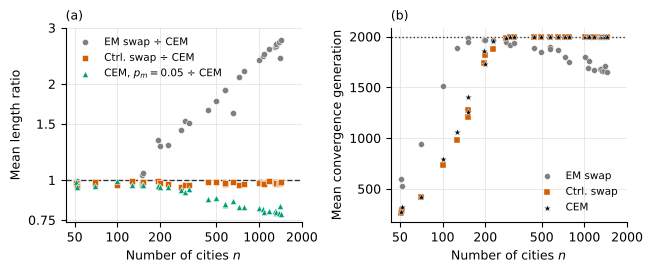

In [29]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.6, 2.8))
a1.scatter(n, AVG['EM_swap'] / AVG['CEM'], c=COL['em'], s=20, label='EM swap ÷ CEM', edgecolor='white', lw=0.4, zorder=3)
a1.scatter(n, AVG['C_swap'] / AVG['CEM'], c=COL['swap'], marker='s', s=20, label='Ctrl. swap ÷ CEM', edgecolor='white', lw=0.4, zorder=3)
e5a = pd.read_csv(one(f'{DATA}/E5_CEM_high_rate/ALL_CEM_summary_*.csv')).set_index('Instance').loc[n.index].Avg
a1.scatter(n, e5a / AVG['CEM'], c=COL['2opt'], marker='^', s=20, label='CEM, $p_m=0.05$ ÷ CEM', edgecolor='white', lw=0.4, zorder=3)
a1.axhline(1, ls='--', c='#333', lw=1); logx(a1)
a1.set_yscale('log'); a1.set_yticks([0.75, 1, 1.5, 2, 3]); a1.set_yticklabels(['0.75', '1', '1.5', '2', '3']); a1.minorticks_off()
a1.set_ylabel('Mean length ratio'); a1.legend(frameon=False, fontsize=7.5); a1.set_title('(a)', loc='left', fontsize=9)
for v, c, mk, lab in [('EM_swap', COL['em'], 'o', 'EM swap'), ('C_swap', COL['swap'], 's', 'Ctrl. swap'), ('CEM', COL['cem'], '*', 'CEM')]:
    a2.scatter(n, CONV[v], c=c, marker=mk, s=28 if mk == '*' else 18, label=lab, edgecolor='white', lw=0.3, zorder=3)
a2.axhline(2000, ls=':', c='#333', lw=1); logx(a2); a2.set_ylabel('Mean convergence generation')
a2.legend(frameon=False, fontsize=7.5, loc='lower right'); a2.set_title('(b)', loc='left', fontsize=9)
fig.tight_layout(); fig.savefig(f'{FIG}/fig11_cem.png'); plt.show()

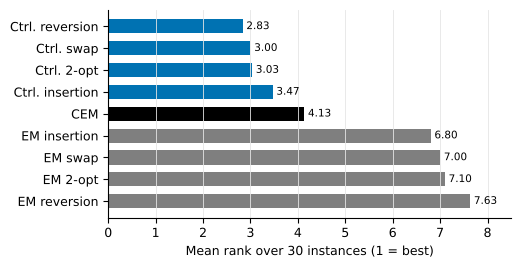

In [30]:
r = S8['Mean rank'][::-1]
cols = [COL['cem'] if v == 'CEM' else (COL['em'] if v.startswith('EM') else COL['ins']) for v in r.index]
fig, ax = plt.subplots(figsize=(5.2, 2.7))
ax.barh([LAB[v] for v in r.index], r.values, color=cols, height=0.65)
for y, x in enumerate(r.values): ax.text(x + 0.08, y, f'{x:.2f}', va='center', fontsize=7.5)
ax.set_xlabel('Mean rank over 30 instances (1 = best)'); ax.grid(axis='y', visible=False); ax.set_xlim(0, 8.5)
fig.savefig(f'{FIG}/fig12_rank9.png'); plt.show()

### E5: CEM at a ten times higher mutation rate

E5 runs CEM with $N=200$, $E=50$ and $p_m=0.05$, about $10n$ mutation attempts per generation against $1.5n$ in E1.

In [31]:
e5 = pd.read_csv(one(f'{DATA}/E5_CEM_high_rate/ALL_CEM_summary_*.csv')).set_index('Instance').loc[n.index]
red5 = 100 * (AVG['CEM'] - e5.Avg) / AVG['CEM']
p5 = pd.Series({i: stats.mannwhitneyu(runs('E5_CEM_high_rate', i, 'CEM').Best, runs('CEM', i, 'CEM').Best, alternative='two-sided').pvalue for i in n.index})
red5c = 100 * (AVG['C_swap'] - e5.Avg) / AVG['C_swap']
T12 = pd.DataFrame({'Inst.': sizebin.value_counts().sort_index(),
                    'E5 vs CEM in E1 (%)': red5.groupby(sizebin, observed=True).median(),
                    'E5 vs ctrl. swap in E1 (%)': red5c.groupby(sizebin, observed=True).median(),
                    'E5 shorter (sig.)': ((p5 < 0.05) & (red5 > 0)).groupby(sizebin, observed=True).sum(),
                    'E5 longer (sig.)': ((p5 < 0.05) & (red5 < 0)).groupby(sizebin, observed=True).sum(),
                    'Conv. E5': e5.AvgConvGen.groupby(sizebin, observed=True).mean(),
                    'Conv. CEM in E1': CONV['CEM'].groupby(sizebin, observed=True).mean()})
print('E5 vs CEM(E1): shorter on', int((red5 > 0).sum()), 'of 30, median', round(red5.median(), 1), '%, signed-rank p =', stats.wilcoxon(e5.Avg, AVG['CEM']).pvalue)
save(T12, 'T12_E5_vs_E1', '%.1f')

E5 vs CEM(E1): shorter on 30 of 30, median 13.3 %, signed-rank p = 1.862645149230957e-09


,Inst.,E5 vs CEM in E1 (%),E5 vs ctrl. swap in E1 (%),E5 shorter (sig.),E5 longer (sig.),Conv. E5,Conv. CEM in E1
n,,,,,,,
≤100,4,2.982610,0.293796,2,0,195.600000,451.550000
101–200,5,3.677760,2.256247,4,0,609.913333,1463.886667
201–500,6,7.475259,4.126204,6,0,1530.222222,1988.511111
501–1000,5,16.501161,14.267630,5,0,1999.460000,1999.400000
>1000,10,20.071573,18.419170,10,0,1999.680000,1999.786667


## 7. Figure 2: the three move types on a small tour

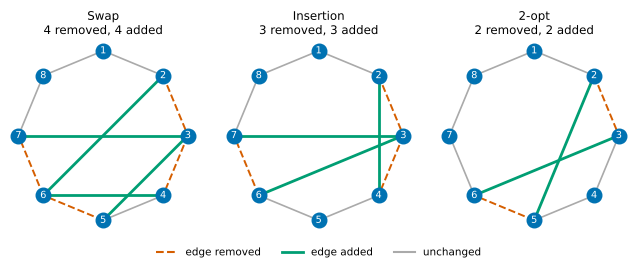

In [32]:
ang = np.pi / 2 - np.arange(8) * 2 * np.pi / 8
P8 = np.c_[np.cos(ang), np.sin(ang)]
base = list(range(8))
moves = {'Swap': [0, 1, 5, 3, 4, 2, 6, 7], 'Insertion': [0, 1, 3, 4, 5, 2, 6, 7], '2-opt': [0, 1, 4, 3, 2, 5, 6, 7]}
edges = lambda t: {frozenset((t[i], t[(i + 1) % 8])) for i in range(8)}
fig, axs = plt.subplots(1, 3, figsize=(6.6, 2.5))
for ax, (name, t) in zip(axs, moves.items()):
    old, new = edges(base), edges(t)
    for e in old & new:
        a, b = tuple(e); ax.plot(*P8[[a, b]].T, c='#aaaaaa', lw=1.2)
    for e in old - new:
        a, b = tuple(e); ax.plot(*P8[[a, b]].T, c=COL['swap'], lw=1.4, ls='--')
    for e in new - old:
        a, b = tuple(e); ax.plot(*P8[[a, b]].T, c=COL['2opt'], lw=2)
    ax.scatter(*P8.T, s=110, c=COL['ins'], zorder=3)
    for k, (x, y) in enumerate(P8): ax.text(x, y, str(k + 1), color='white', ha='center', va='center', fontsize=7, zorder=4)
    ax.set_title(f'{name}\n{len(old - new)} removed, {len(new - old)} added', fontsize=8.5); ax.set_aspect('equal'); ax.axis('off')
h = [plt.Line2D([], [], c=COL['swap'], ls='--'), plt.Line2D([], [], c=COL['2opt'], lw=2), plt.Line2D([], [], c='#aaaaaa')]
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.legend(h, ['edge removed', 'edge added', 'unchanged'], ncol=3, frameon=False, loc='lower center', fontsize=7.5, bbox_to_anchor=(0.5, 0.0)); fig.savefig(f'{FIG}/fig2_moves.png'); plt.show()